In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('heart_disease.csv', na_values='?').dropna()

df['target'] = (df['num'] > 0).astype(int)

X = df.drop(columns=['num', 'target'])
y = df.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"training no : {X_train.shape[0]},  testing no: {X_test.shape[0]}")

training no : 237,  testing no: 60


## SVM

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

svm = SVC(kernel='rbf')
svm.fit(X_train_s, y_train)

print('SVM accuracy:', round(svm.score(X_test_s, y_test), 3))
print(classification_report(y_test, svm.predict(X_test_s),
                            target_names=['no disease', 'disease']))

SVM accuracy: 0.85
              precision    recall  f1-score   support

  no disease       0.83      0.91      0.87        32
     disease       0.88      0.79      0.83        28

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60



The SVM lands around **85% accuracy** with solid recall on the `disease` class. That's the number our decision tree needs to beat.

## Part 2 — Decision Tree

Now the tree. Notice what we *don't* do: **no scaling**. A tree asks questions like *"is cholesterol > 240?"* — rescaling the numbers wouldn't change which side of the split a patient falls on, so it's simply unnecessary. We train straight on the raw features.

In [3]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

print(f"Training Accuracy: {tree.score(X_train, y_train)}")
print(f"Testing Accuracy: {tree.score(X_test, y_test)}")

print(classification_report(y_test, tree.predict(X_test),
                            target_names=['no disease', 'disease']))

Training Accuracy: 1.0
Testing Accuracy: 0.7
              precision    recall  f1-score   support

  no disease       0.71      0.75      0.73        32
     disease       0.69      0.64      0.67        28

    accuracy                           0.70        60
   macro avg       0.70      0.70      0.70        60
weighted avg       0.70      0.70      0.70        60



In [7]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

print('Decision Tree (max_depth=3) — train accuracy:', round(tree.score(X_train, y_train), 3))
print('Decision Tree (max_depth=3) — test accuracy: ', round(tree.score(X_test, y_test), 3))
print(classification_report(y_test, tree.predict(X_test),
                            target_names=['no disease', 'disease']))

Decision Tree (max_depth=3) — train accuracy: 0.844
Decision Tree (max_depth=3) — test accuracy:  0.8
              precision    recall  f1-score   support

  no disease       0.81      0.81      0.81        32
     disease       0.79      0.79      0.79        28

    accuracy                           0.80        60
   macro avg       0.80      0.80      0.80        60
weighted avg       0.80      0.80      0.80        60



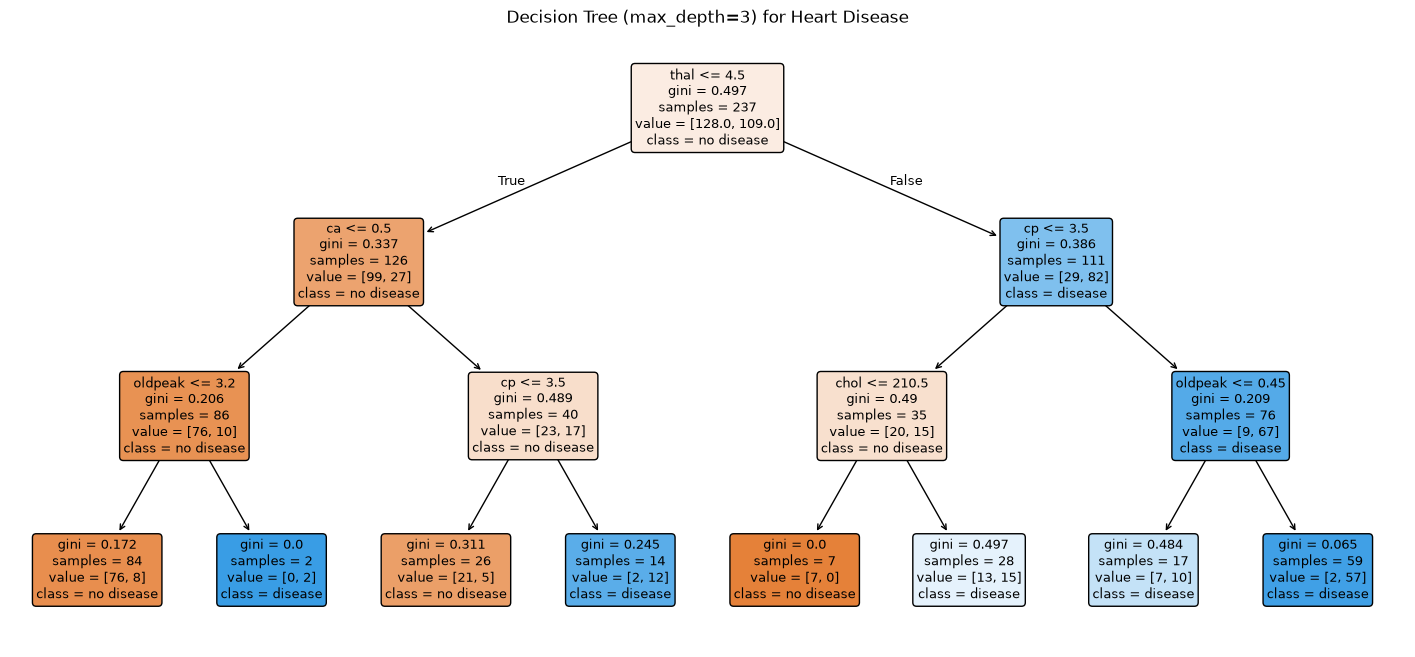

In [9]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=X.columns, class_names=['no disease', 'disease'],
          filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree (max_depth=3) for Heart Disease')
plt.show()

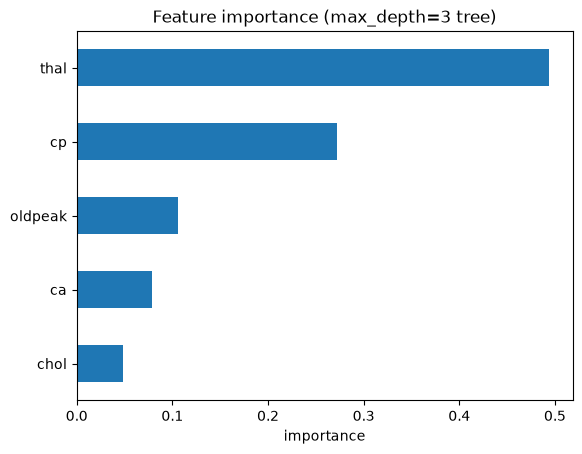

In [10]:
importances = pd.Series(tree.feature_importances_, index=X.columns)
importances  = importances[importances > 0].sort_values()

importances.plot(kind='barh')
plt.xlabel('importance')
plt.title('Feature importance (max_depth=3 tree)')
plt.show()